### Importing Model

In [2]:
import message_ix
import ixmp as ix
from ixmp import Scenario
from message_ix import make_df
from pre_process.prov_parameters import generator,remove_canada_data, remove_technology_data
import pandas as pd
from pathlib import Path

<IPython.core.display.Javascript object>

## Initialize scenario

In [3]:
 # Stand-alone model
modelName = 'MESSAGEix_CA_provincial'      # A MESSAGE model name
scenarioName = 'baseline'       # A MESSAGE model scenario name
ssp = 'SSP2'

mp = ix.Platform(name = 'p3')

# Creating a new MESSAGE stand-alone model
msg = message_ix.Scenario(mp, modelName, scenarioName,
                            version='new', annotation='')

2024-04-03 11:28:53,872  INFO at.ac.iiasa.ixmp.Platform:165 - Welcome to the IX modeling platform!
2024-04-03 11:28:53,879  INFO at.ac.iiasa.ixmp.Platform:166 -  connected to database 'jdbc:hsqldb:file:/Users/muhammadawais/.local/share/ixmp' (user: ixmp)...


In [4]:
# Path to data folder
DATA = Path().cwd().parent / 'data'
TEST = Path().cwd().parent / 'test'

In [5]:
# Read in data from Canadian scenario
msg.read_excel(DATA / 'data_CA_provinicial_v3.xlsx',
               add_units=True, 
               commit_steps=False,
               init_items = True)

### Adding Import & Export Data

In [7]:
df = pd.read_excel(DATA /'provincial_sources/Natural_Gas_Data.xlsx')

In [8]:
df

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,Province,Export_ Volume (10³ m³)(2011-2015),Export_ Volume (10³ m³) (2016-2020),Gas Export_ GWa (2011-2015),Gas Export_ Gwa (2016-2020),Import_ Volume (10³ m³)(2011-2015),Import_ Volume (10³ m³)(2016-2020),Gas Import_ Volume (10³ m³)(2011-2015),Gas Import_ GWa(2016-2020)
1,AB,3208272.762829,4416273.405892,3.785762,5.211203,0,0,0,0
2,NB,10936678.5371,3480728.35168,12.905281,4.107259,1058274.139526,3482153.451052,1.248763,4.108941
3,ON,35712104.867949,28173279.846668,42.140284,33.24447,120187725.569936,111508590.394158,141.821516,131.580137
4,QC,9424519.678462,13424003.248901,11.120933,15.840324,0,14934.341622,0,0.017623
5,SK,164621108.625901,139126360.741538,194.252908,164.169106,0,51255.1,0,0.060481
6,MB,52859883.026651,48866594.418969,62.374662,57.662581,1263125.871399,1227771.802717,1.490489,1.448771
7,BC,133587932.057463,158934006.744018,157.63376,187.542128,893254.47628,1549190.954853,1.05404,1.828045
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
msg.add_par('resource_remaining',par_rem)

In [ ]:
demand = msg.par('demand')

In [79]:
msg.remove_par('demand',demand)

In [60]:
nodes_to_check = ['Alberta', 'BritishColumbia']
node_condition = demand['node'].isin(nodes_to_check)
commodity_condition = demand['commodity'].str.contains('i_feed')

# Combine both conditions using '&' (logical AND)
combined_condition = node_condition & commodity_condition

# Apply the combined condition to modify the 'value' column
demand.loc[combined_condition, 'value'] *= 0.8

In [61]:
nodes_to_check = ['Yukon']
node_condition = demand['node'].isin(nodes_to_check)
commodity_condition = demand['commodity'].str.contains('i_spec')

# Combine both conditions using '&' (logical AND)
combined_condition = node_condition & commodity_condition

# Apply the combined condition to modify the 'value' column
demand.loc[combined_condition, 'value'] *= 0.8

In [62]:
# Assuming par_new is already loaded with the 'par.csv' data
condition = (demand['node'].isin(['Quebec']))
demand.loc[condition, 'value'] *= 0.8

In [72]:
msg.add_par('demand', demand)

In [29]:
par_new['value'] = par_new['value']* 20

In [30]:
nodes_to_check = ['Ontario', 'Alberta', 'Quebec', 'Saskatchewan', 'British Columbia', 'Northwest Territories']
node_condition = par_new['node'].isin(nodes_to_check)
commodity_condition = par_new['commodity'].str.contains('crude')

# Combine both conditions using '&' (logical AND)
combined_condition = node_condition & commodity_condition

# Apply the combined condition to modify the 'value' column
par_new.loc[combined_condition, 'value'] *= 30

In [31]:
# Assuming par_new is already loaded with the 'par.csv' data
condition = (par_new['node'].str.contains('New')) & (par_new['commodity'].str.contains('crude'))
par_new.loc[condition, 'value'] *= 18



In [32]:
# Assuming par_new is already loaded with the 'par.csv' data
condition = (par_new['node'].str.contains('North')) & (par_new['commodity'].str.contains('crude'))
par_new.loc[condition, 'value'] *= 18


In [33]:
par_new[(par_new['node'].str.contains('North')) & (par_new['commodity'].str.contains('crude'))]

,node,commodity,grade,value,unit
103,NorthwestTerritories,crude_1,a,255.992115,GWa
104,NorthwestTerritories,crude_2,a,1158.419466,GWa
105,NorthwestTerritories,crude_3,a,466.960697,GWa
106,NorthwestTerritories,crude_4,a,2932.050268,GWa
107,NorthwestTerritories,crude_5,a,1793.109648,GWa
108,NorthwestTerritories,crude_6,a,16247.531331,GWa
109,NorthwestTerritories,crude_7,a,28433.241788,GWa


In [34]:
msg.add_par('resource_volume',par_new)

In [12]:
msg.commit('Adjust resource volumes')

In [14]:
par_new.to_csv('par.csv')

In [36]:
df = par_new.loc[par_new["value"] > 0].copy().set_index("commodity")
parname = "historical_activity"
dict_fuel = {"crude_": "oil_extr_", "gas_": "gas_extr_"}

In [37]:
par_new

,node,commodity,grade,value,unit
0,Alberta,coal,a,2.873101e+05,GWa
1,Alberta,coal,c,5.450169e+05,GWa
2,Alberta,coal,d,3.936233e+05,GWa
3,Alberta,crude_1,a,1.100519e+04,GWa
4,Alberta,crude_2,a,2.497594e+06,GWa
...,...,...,...,...,...
255,Yukon,gas_6,a,5.329889e+04,GWa
256,Yukon,lignite,a,0.000000e+00,GWa
257,Yukon,lignite,c,0.000000e+00,GWa
258,Yukon,lignite,d,0.000000e+00,GWa


In [38]:
msg.check_out()

In [39]:
import pandas as pd


# Assuming 'nodeName' is a column in 'par.csv' that corresponds to the node
unique_nodes = par_new['node'].unique()
parname = "historical_activity"
dict_fuel = {"crude_": "oil_extr_", "gas_": "gas_extr_"}

for nodeName in unique_nodes:
    df = par_new[par_new["node"] == nodeName]
    df = df[df["value"] > 0].copy().set_index("commodity")

    for com in dict_fuel.keys():
        tec_hist = dict_fuel[com] + str(1)
        df_hist = msg.par(parname, {"technology": tec_hist, "node_loc": nodeName})
        df_new = pd.DataFrame(columns=df_hist.columns)

        if df_hist.empty or df_hist[df_hist["value"] > 0].empty:
            continue

        for yr in df_hist["year_act"].tolist():
            hist_ref = float(df_hist.loc[df_hist["year_act"] == yr, "value"])

            for i in range(1, 8):
                commodity = com + str(i)
                if commodity not in df.index:
                    continue
                tec = dict_fuel[com] + str(i)
                share = 0.9  # Directly using 0.9 instead of fetching from sheet_res
                if share * df["value"][commodity] < hist_ref:
                    df_hist_new = df_hist.loc[df_hist["year_act"] == yr].copy()
                    df_hist_new["technology"] = tec
                    df_hist_new["value"] = share * df["value"][commodity]
                    df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
                    hist_ref -= share * df["value"][commodity]
                elif i > 1:
                    df_hist_new = df_hist.loc[df_hist["year_act"] == yr].copy()
                    df_hist_new["technology"] = tec
                    df_hist_new["value"] = hist_ref
                    df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
                    break
                else:
                    df_hist_new = df_hist.loc[df_hist["year_act"] == yr].copy()
                    df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
                    break

        if com + str(1) not in df.index:
            msg.remove_par(parname, df_hist)
            df_new = df_new.loc[df_new["technology"] != dict_fuel[com] + str(1)].copy()

        msg.add_par(parname, df_new)

print("> Historical activity of extraction technologies updated based on new resource volumes.")


/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_43988/314639121.py:22: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  hist_ref = float(df_hist.loc[df_hist["year_act"] == yr, "value"])
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_43988/314639121.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_43988/314639121.py:22: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  hist_ref = float(df_hist.loc[df_hist["yea

> Historical activity of extraction technologies updated based on new resource volumes.


/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_43988/314639121.py:22: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  hist_ref = float(df_hist.loc[df_hist["year_act"] == yr, "value"])
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_43988/314639121.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_new = pd.concat([df_new, df_hist_new], ignore_index=True)
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_43988/314639121.py:22: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  hist_ref = float(df_hist.loc[df_hist["yea

In [40]:
# 4) Adjustment of historical activity of market penetration technologies
for t in ["oil_extr", "gas_extr", "coal_extr"]:
    mpen = t + "_mpen"
    tec_list = [x for x in set(msg.set("technology")) if t in x and x != mpen]

    if t == "coal_extr":
        tec_list = tec_list + ["lignite_extr"]

    df = msg.par("historical_activity", {"technology": tec_list})
    df["technology"] = mpen
    df = df.groupby(msg.idx_names("historical_activity") + ["unit"]).sum()
    msg.add_par("historical_activity", df.reset_index())


In [41]:
msg.add_set('technology','gas_extr_7')

## New Version

In [89]:
# Read in data from Canadian scenario
msg.read_excel(DATA / 'data_CA_provincial_v2.xlsx',
               add_units=True, 
               commit_steps=False,
               init_items = True)

In [90]:
df_renew_pot = pd.read_csv(DATA / 'CODERS_data/renewable_potential.csv')

df_renew_pot['node'] = df_renew_pot['node'].str.replace(' ', '')['node'] = df_renew_pot['node'].str.replace(' ', '')
df_renew_pot['value'] = df_renew_pot['value']/1e3
df_renew_pot['unit'] ='GWa'

In [91]:
msg.check_out()
msg.add_par('renewable_potential',df_renew_pot )

In [82]:
df_renew_pot.to_csv(DATA / 'provincial_sources/renewable_potential.csv')

In [83]:
df = msg.par('renewable_potential')

In [50]:
msg.remove_par('renewable_potential',df)

In [51]:
df['value'] = df['value'] *3

In [52]:
msg.add_par('renewable_potential',df )

In [47]:
df[df['commodity'] == 'hydro']

,node,commodity,grade,level,year,value,unit
1983,Alberta,hydro,c1,renewable,2020,500.000000,GWa
1988,Alberta,hydro,c1,renewable,2025,500.000000,GWa
1993,Alberta,hydro,c1,renewable,2030,500.000000,GWa
1998,Alberta,hydro,c1,renewable,2035,500.000000,GWa
2003,Alberta,hydro,c1,renewable,2040,500.000000,GWa
...,...,...,...,...,...,...,...
2939,Yukon,hydro,c1,renewable,2040,0.000012,GWa
2944,Yukon,hydro,c1,renewable,2045,0.000012,GWa
2949,Yukon,hydro,c1,renewable,2050,0.000012,GWa
2954,Yukon,hydro,c1,renewable,2055,0.000012,GWa


In [25]:
df_renew_cap

,node,commodity,grade,level,year,value,unit
0,BritishColumbia,wind_onshore,c1,renewable,1960,0.18,-
1,BritishColumbia,wind_onshore,c2,renewable,1960,0.20,-
2,BritishColumbia,wind_onshore,c3,renewable,1960,0.24,-
3,BritishColumbia,wind_onshore,c4,renewable,1960,0.28,-
4,BritishColumbia,wind_onshore,c5,renewable,1960,0.32,-
...,...,...,...,...,...,...,...
4615,PrinceEdwardIsland,solar_pv,c4,renewable,2060,0.15,-
4616,PrinceEdwardIsland,solar_pv,c5,renewable,2060,0.17,-
4617,PrinceEdwardIsland,solar_pv,c6,renewable,2060,0.19,-
4618,PrinceEdwardIsland,solar_pv,c7,renewable,2060,0.22,-


In [92]:
df_renew_cap = pd.read_csv(DATA / 'CODERS_data/renewable_capacity_factor.csv')
df_renew_cap['node'] = df_renew_cap['node'].str.replace(' ', '')['node'] = df_renew_cap['node'].str.replace(' ', '')
df_renew_cap.to_csv(DATA / 'provincial_sources//renewable_capacity_factor.csv')

In [93]:
msg.add_par('renewable_capacity_factor', df_renew_cap)

In [94]:
# msg.check_out()
df = msg.par('growth_activity_lo')
msg.remove_par('growth_activity_lo', df)
filtered_df = df[~df['technology'].isin(['hydro_lc', 'hydro_hc','solar_pv_ppl'])]
msg.add_par('growth_activity_lo',filtered_df) 

In [95]:
# msg.check_out()
df = msg.par('initial_activity_lo')
msg.remove_par('initial_activity_lo', df)
filtered_df = df[~df['technology'].isin(['hydro_lc', 'hydro_hc','solar_pv_ppl'])]
msg.add_par('initial_activity_lo',filtered_df) 

In [108]:
msg.to_excel(DATA /'data_CA_provinicial_v3.xlsx')

/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_

In [ ]:
msg.to_excel(DATA /'data_CA_provinicial_v5.xlsx')

In [5]:
# Read in data from Canadian scenario
msg.read_excel(DATA / 'data_CA_provinicial_v3.xlsx',
               add_units=True, 
               commit_steps=False,
               init_items = True)

## Solve Model

In [6]:
msg.model
msg.version
msg.commit('')

RuntimeError: this Scenario is not checked out, no changes to be committed!

In [8]:
caseName

'MESSAGEix_CA_provincial__baseline__v26'

In [7]:
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)

In [9]:
# Solving the model
msg.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 04/02/24 19:13:35 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__baseline__v26.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__baseline__v26.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__baseline__v26.gdx
Licensee: Small MUD - 5 User License         

2024-04-02 19:14:16,871 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-04-02 19:14:16,879 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


## Other Scenarios

Now making another scenario cloned from baseline to add other policies. 

Policy No. 1
Baseline - NDC 
Implement Canada's commitments 
msg = msg.clone(keep_solution=False)

In [ ]:
import matplotlib.pyplot as plt
import pyam

In [8]:
msg.version

25

In [31]:
msg.has_solution()

True

In [10]:
from message_ix.report import Reporter
from pre_process.update_units import unit_correction
import numpy as np
unit_correct = False  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

if unit_correct:
    msg1 = msg.clone(keep_solution=False)
    unit_correction(mp, msg1)
    caseName = msg1.model + '__' + msg1.scenario + '__v' + str(msg1.version)
    # Solving the model
    msg1.solve(model='MESSAGE', case=caseName, solve_options={'barcrossalg': '2','lpmethod':'1'})

In [12]:
from message_ix.report import Reporter
from pre_process.update_units import unit_correction
import numpy as np
unit_correct = False  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

if unit_correct:
    msg = msg.clone(keep_solution=False)
    unit_correction(mp, msg)
    caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)
    # Solving the model
    msg.solve(model='MESSAGE', case=caseName, solve_options={'barcrossalg': '2','lpmethod':'1'})

#%% Generating reporter

rep = Reporter.from_scenario(msg, units={"apply": {"var_cost": ""}})
report = rep.get('message::default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
ixmp.report.operator - WARNING: emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
output: mixed un

In [13]:
report_df

,Model,Scenario,Region,Variable,Unit,2010,2015,2020,2025,2030,2035,2040,2045,2050,2055,2060
0,MESSAGEix_CA_provincial,baseline,Alberta,CAP_NEW|new capacity|LNG_exp,,0.0,0.0,0.067645,0.109214,0.176326,0.28468,0.459617,0.8097,1.307267,2.110592,3.407566
1,MESSAGEix_CA_provincial,baseline,Alberta,CAP_NEW|new capacity|adipic_thermal,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
2,MESSAGEix_CA_provincial,baseline,Alberta,CAP_NEW|new capacity|ammonia_secloop,,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
3,MESSAGEix_CA_provincial,baseline,Alberta,CAP_NEW|new capacity|bio_hpl,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
4,MESSAGEix_CA_provincial,baseline,Alberta,CAP_NEW|new capacity|bio_hpl__air,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38150,MESSAGEix_CA_provincial,baseline,Yukon|Yukon,out|water_supply_constraint|water_constraint|e...,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
38151,MESSAGEix_CA_provincial,baseline,Yukon|Yukon,out|water_supply|freshwater_instream|extract__...,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
38152,MESSAGEix_CA_provincial,baseline,Yukon|Yukon,out|water_supply|freshwater_supply|extract__fr...,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000
38153,MESSAGEix_CA_provincial,baseline,Yukon|Yukon,out|water_supply|saline_supply|extract__saline...,,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000


In [30]:
from iam_units import registry
u1 = registry.Unit("USD / kWa")
u2 = registry.Unit("USD / a / kW")
u1.is_compatible_with(u2)

True

In [15]:
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
c = report_df.select_dtypes(include=[np.number]) * 8.76
report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = pd.concat([out_flows , in_flows])

In [60]:
mp.close_db()

In [16]:
report_df.to_csv('MESSAGE_CANADA_provincial_v4.csv')

In [17]:
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('emis', 'Emissions', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)

In [18]:
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
pdf = pyam_df.copy()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/utils.py:347: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df.set_index(index + REQUIRED_COLS + extra_cols)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [22]:

biomass = ['Primary Energy|biomass|bio_istig_ccs|M1', 
'Primary Energy|biomass|bio_istig|M1']
#'Primary Energy|biomass|bio_ppl|M1',
#'Primary Energy|biomass|biomass_nc|M1',
#'Primary Energy|biomass|biomass_t_d|M1',
#'Primary Energy|biomass|eth_bio_ccs|M1',
#'Primary Energy|biomass|eth_bio|M1',
#'Primary Energy|biomass|gas_bio|M1',
#'Primary Energy|biomass|h2_bio_ccs|M1',
#'Primary Energy|biomass|h2_bio|M1',
#'Primary Energy|biomass|liq_bio_ccs|M1',
#'Primary Energy|biomass|liq_bio|M1','Primary Energy|biomass|land_use_biomass|M1']

lng = ['Primary Energy|LNG|LNG_bal|M1']

coal = ['Primary Energy|coal|coal_bal|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_extr_ch4|M1',
                      'Primary Energy|coal|coal_extr|M1',
                      'Primary Energy|coal|lignite_extr|M1']

gas = [#'Primary Energy|gas|gas_bal|M1',
    'Primary Energy|gas|gas_extr_1|M1',
      'Primary Energy|gas|gas_extr_2|M1',
      'Primary Energy|gas|gas_extr_3|M1',
      'Primary Energy|gas|gas_extr_4|M1',
      'Primary Energy|gas|gas_extr_5|M1',
      'Primary Energy|gas|gas_extr_6|M1']
      #'Primary Energy|gas|LNG_prod|M1']
      # 'Primary Energy|LNG|LNG_bal|M1']

oil = [#'Primary Energy|crudeoil|oil_bal|M1',
    'Primary Energy|crudeoil|oil_exp|M1',
     # 'Primary Energy|crudeoil|oil_extr_1_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_1|M1',
       # 'Primary Energy|crudeoil|oil_extr_2_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_2|M1',
      #  'Primary Energy|crudeoil|oil_extr_3_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_3|M1',
        #'Primary Energy|crudeoil|oil_extr_4_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_4|M1',
        'Primary Energy|crudeoil|oil_extr_5|M1',
        'Primary Energy|crudeoil|oil_extr_6|M1',
        'Primary Energy|crudeoil|oil_extr_7|M1']

hydro = ['Primary Energy|renewable|hydro|hydro_hc|M1',  'Primary Energy|renewable|hydro|hydro_lc|M1']

biomass_renew = ['Primary Energy|renewable|biomass|bio_extr_a|M1',
                'Primary Energy|renewable|biomass|bio_extr_b|M1',
                'Primary Energy|renewable|biomass|bio_extr_c|M1',
                'Primary Energy|renewable|biomass|bio_extr_d|M1',
                'Primary Energy|renewable|biomass|bio_extr_e|M1',
                'Primary Energy|renewable|biomass|bio_extr_f|M1',
                'Primary Energy|renewable|biomass|bio_extr_g|M1']

solar = ['Primary Energy|renewable|solar_pv|solar_pv_ppl|M1' , 
         'Primary Energy|renewable|solar_th|solar_th_ppl|M1']


wind = ['Primary Energy|renewable|wind|wind_ppf|M1', 'Primary Energy|renewable|wind|wind_ppl|M1']

lh2 = ['Primary Energy|lh2|lh2_bal|M1', 'Primary Energy|lh2|lh2_exp|M1']

ethanol = ['Primary Energy|methanol|meth_bal|M1',  'Primary Energy|methanol|meth_exp|M1']

methanol = ['Primary Energy|ethanol|eth_bal|M1', 'Primary Energy|ethanol|eth_exp|M1']



In [23]:
pdf = pyam_df.copy()


In [24]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

In [25]:
pdf.filter(variable = 'Primary Energy|gas').timeseries()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


2010  \
model                   scenario region                                          variable           unit         
MESSAGEix_CA_provincial baseline Alberta|Alberta                                 Primary Energy|gas        0.0   
                                 BritishColumbia|BritishColumbia                 Primary Energy|gas        0.0   
                                 Manitoba|Manitoba                               Primary Energy|gas        0.0   
                                 NewBrunswick|NewBrunswick                       Primary Energy|gas        0.0   
                                 NewfoundlandandLabrador|NewfoundlandandLabrador Primary Energy|gas        0.0   
                                 NorthwestTerritories|NorthwestTerritories       Primary Energy|gas        0.0   
                                 NovaScotia|NovaScotia                           Primary Energy|gas        0.0   
                                 Nunavut|Nunavut                                 Primary Energy|gas        0.0   
                                 Ontario|Ontario                                 Primary Energy|gas        0.0   
                                 PrinceEdwardIsland|PrinceEdwardIsland           Primary Energy|gas        0.0   
                                 Quebec|Quebec                                   Primary Energy|gas        0.0   
                                 Saskatchewan|Saskatchewan                       Primary Energy|gas        0.0   
                                 Yukon|Yukon                                     Primary Energy|gas        0.0   

                                                                                                          2015  \
model                   scenario region                                          variable           unit         
MESSAGEix_CA_provincial baseline Alberta|Alberta                                 Primary Energy|gas        0.0   
                                 BritishColumbia|BritishColumbia                 Primary Energy|gas        0.0   
                                 Manitoba|Manitoba                               Primary Energy|gas        0.0   
                                 NewBrunswick|NewBrunswick                       Primary Energy|gas        0.0   
                                 NewfoundlandandLabrador|NewfoundlandandLabrador Primary Energy|gas        0.0   
                                 NorthwestTerritories|NorthwestTerritories       Primary Energy|gas        0.0   
                                 NovaScotia|NovaScotia                           Primary Energy|gas        0.0   
                                 Nunavut|Nunavut                                 Primary Energy|gas        0.0   
                                 Ontario|Ontario                                 Primary Energy|gas        0.0   
                                 PrinceEdwardIsland|PrinceEdwardIsland           Primary Energy|gas        0.0   
                                 Quebec|Quebec                                   Primary Energy|gas        0.0   
                                 Saskatchewan|Saskatchewan                       Primary Energy|gas        0.0   
                                 Yukon|Yukon                                     Primary Energy|gas        0.0   

                                                                                                                2020  \
model                   scenario region                                          variable           unit               
MESSAGEix_CA_provincial baseline Alberta|Alberta                                 Primary Energy|gas       235.587127   
                                 BritishColumbia|BritishColumbia                 Primary Energy|gas        20.166571   
                                 Manitoba|Manitoba                               Primary Energy|gas         0.000000   
                                 NewBrunswick|NewBrunswick                       Pri

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

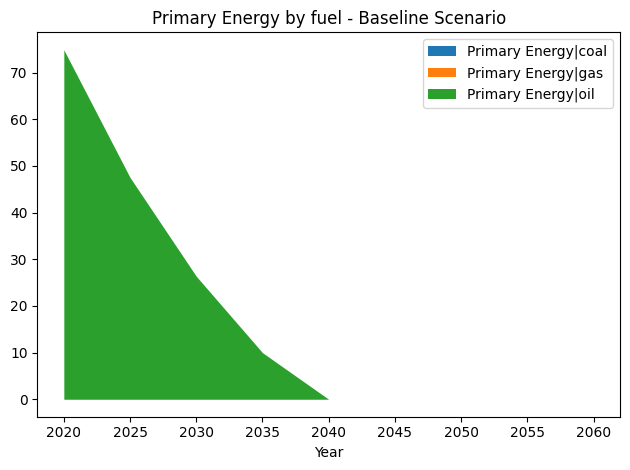

In [28]:
data = pdf.filter( variable=["Primary Energy|renewable|solar",
                                            #"Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs, region = 'Yukon|Yukon')

data.plot.stack(title = 'Primary Energy by fuel - Baseline Scenario')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [29]:
i_feed = ['Useful Energy|i_feed|ethanol_fs|M1', 'Useful Energy|i_feed|gas_fs|M1',
         'Useful Energy|i_feed|loil_fs|M1', 'Useful Energy|i_feed|methanol_fs|M1']

transport = ['Useful Energy|transport|coal_trp|M1',
            'Useful Energy|transport|elec_trp|M1',
            'Useful Energy|transport|eth_fc_trp|M1',
            'Useful Energy|transport|eth_ic_trp|M1',
            'Useful Energy|transport|foil_trp|M1',
            'Useful Energy|transport|gas_trp|M1',
            'Useful Energy|transport|h2_fc_trp|M1',
            'Useful Energy|transport|loil_trp|M1',
            'Useful Energy|transport|meth_fc_trp|M1',
            'Useful Energy|transport|meth_ic_trp|M1']


i_spec = ['Useful Energy|i_spec|h2_fc_I|M1',
          'Useful Energy|i_spec|sp_coal_I|M1',
          'Useful Energy|i_spec|sp_el_I|M1',
          'Useful Energy|i_spec|sp_eth_I|M1',
          'Useful Energy|i_spec|sp_liq_I|M1',
          'Useful Energy|i_spec|sp_meth_I|M1']

i_therm =   ['Useful Energy|i_therm|biomass_i|M1',
            'Useful Energy|i_therm|coal_i|M1',
            'Useful Energy|i_therm|elec_i|M1',
            'Useful Energy|i_therm|eth_i|M1',
            'Useful Energy|i_therm|foil_i|M1',
            'Useful Energy|i_therm|gas_i|M1',
            'Useful Energy|i_therm|h2_fc_I|M1',
            'Useful Energy|i_therm|h2_i|M1',
            'Useful Energy|i_therm|heat_i|M1',
            'Useful Energy|i_therm|hp_el_i|M1',
            'Useful Energy|i_therm|hp_gas_i|M1',
            'Useful Energy|i_therm|loil_i|M1',
            'Useful Energy|i_therm|meth_i|M1',
            'Useful Energy|i_therm|solar_i|M1']
rc_spec = ['Useful Energy|rc_spec|h2_fc_RC|M1',
          'Useful Energy|rc_spec|sp_el_RC|M1']

rc_therm = ['Useful Energy|rc_therm|biomass_rc|M1',
            'Useful Energy|rc_therm|coal_rc|M1',
            'Useful Energy|rc_therm|eth_rc|M1',
            'Useful Energy|rc_therm|foil_rc|M1',
            'Useful Energy|rc_therm|gas_rc|M1',
            'Useful Energy|rc_therm|h2_fc_RC|M1',
            'Useful Energy|rc_therm|h2_rc|M1',
            'Useful Energy|rc_therm|heat_rc|M1',
            'Useful Energy|rc_therm|hp_el_rc|M1',
            'Useful Energy|rc_therm|hp_gas_rc|M1',
            'Useful Energy|rc_therm|loil_rc|M1',
            'Useful Energy|rc_therm|meth_rc|M1',
            'Useful Energy|rc_therm|solar_rc|M1']

biom = ['Useful Energy|non-comm|biomass_nc|M1']

In [30]:
df_useful = pyam_df.copy()
# df_useful.aggregate(
#     "Useful Energy|non-Commercial biomass",
#     components=biom,
#     append=True
# )

df_useful.aggregate(
    "Useful Energy|residential/commercial thermal",
    components=rc_therm,
    append=True
)

df_useful.aggregate(
    "Useful Energy|residential/commercial specific",
    components=rc_spec,
    append=True
)

df_useful.aggregate(
    "Useful Energy|industrial thermal",
    components=i_therm,
    append=True
)

df_useful.aggregate(
    "Useful Energy|industrial specific",
    components=i_spec,
    append=True
)

df_useful.aggregate(
    "Useful Energy|industrial feedstock",
    components=i_feed,
    append=True
)

df_useful.aggregate(
    "Useful Energy|transport",
    components=i_therm,
    append=True
)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

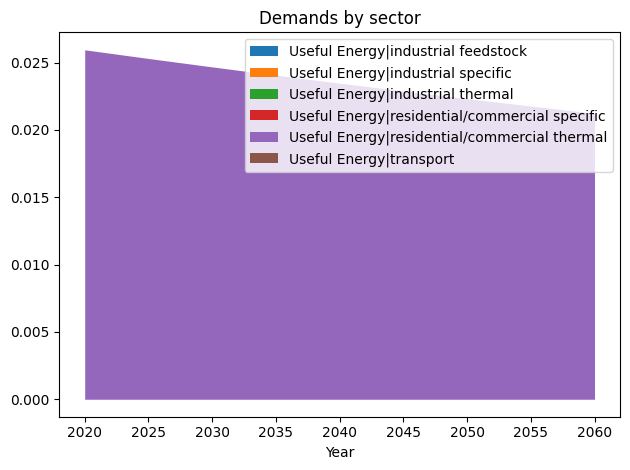

In [32]:
data = df_useful.filter(scenario = 'baseline', variable=[
    "Useful Energy|non-Commercial biomass",
    "Useful Energy|residential/commercial thermal",
    "Useful Energy|residential/commercial specific",
    "Useful Energy|industrial thermal",
    "Useful Energy|industrial specific",
    "Useful Energy|industrial feedstock",
    "Useful Energy|transport"],
              year = plotyrs, region = 'Yukon|Yukon')


data.plot.stack(title = 'Demands by sector')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [33]:
cement = ['Emissions|CO2|cement_CO2|M1']
coal = ['Emissions|CO2|coal_extr_ch4|M1',
        'Emissions|CO2|coal_extr|M1',
        'Emissions|CO2|coal_imp|M1']
foil = ['Emissions|CO2|foil_imp|M1']
gas = ['Emissions|CO2|gas_extr_1|M1',
        'Emissions|CO2|gas_extr_2|M1',
        'Emissions|CO2|gas_extr_3|M1',
        'Emissions|CO2|gas_extr_4|M1',
        'Emissions|CO2|gas_extr_5|M1',
        'Emissions|CO2|gas_extr_6|M1'
        ]
lignite = ['Emissions|CO2|lignite_extr|M1']
loil = ['Emissions|CO2|loil_imp|M1']
meth_ccs = ['Emissions|CO2|meth_coal_ccs|M1']
oil = ['Emissions|CO2|oil_extr_1_ch4|M1',
    'Emissions|CO2|oil_extr_1|M1',
    'Emissions|CO2|oil_extr_2_ch4|M1',
    'Emissions|CO2|oil_extr_2|M1',
    'Emissions|CO2|oil_extr_3_ch4|M1',
    'Emissions|CO2|oil_extr_3|M1',
    'Emissions|CO2|oil_extr_4_ch4|M1',
    'Emissions|CO2|oil_extr_4|M1',
    'Emissions|CO2|oil_extr_5|M1',
    'Emissions|CO2|oil_extr_6|M1',
    'Emissions|CO2|oil_extr_7|M1']

oil_trade = ['Emissions|CO2|foil_imp|M1',
             'Emissions|CO2|loil_exp|M1',
            'Emissions|CO2|loil_imp|M1',
             'Emissions|CO2|oil_imp|M1']
       
gas_trade = ['Emissions|CO2|LNG_exp|M1',
            'Emissions|CO2|LNG_imp|M1',
            'Emissions|CO2|gas_imp|M1']
            #'Emissions|CO2|LNG_exp|M1']

In [34]:
df_emis_b = pyam_df.filter(variable = 'Emissions|CO2|*',year = plotyrs)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [ ]:
df_emis_b.to_csv('emissions.csv')

In [35]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

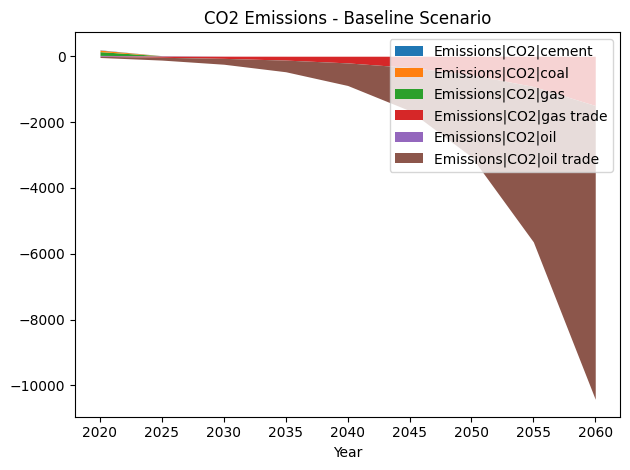

In [42]:
data = df_emis.filter(scenario = 'baseline', variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement",
    "Emissions|CO2|oil trade",
    "Emissions|CO2|gas trade"],
              year = plotyrs, region = 'Alberta')

data.plot.stack(title = 'CO2 Emissions - Baseline Scenario')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [43]:
df_emis.aggregate('Emissions|*').timeseries()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/utils.py:574: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.
  matches |= data.str.match(pattern) & depth
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in 

2010  \
model                   scenario region                  variable    unit         
MESSAGEix_CA_provincial baseline Alberta                 Emissions|*        0.0   
                                 BritishColumbia         Emissions|*        0.0   
                                 Manitoba                Emissions|*        0.0   
                                 NewBrunswick            Emissions|*        0.0   
                                 NewfoundlandandLabrador Emissions|*        0.0   
                                 NorthwestTerritories    Emissions|*        0.0   
                                 NovaScotia              Emissions|*        0.0   
                                 Nunavut                 Emissions|*        0.0   
                                 Ontario                 Emissions|*        0.0   
                                 PrinceEdwardIsland      Emissions|*        0.0   
                                 Quebec                  Emissions|*        0.0   
                                 Saskatchewan            Emissions|*        0.0   
                                 Yukon                   Emissions|*        0.0   

                                                                           2015  \
model                   scenario region                  variable    unit         
MESSAGEix_CA_provincial baseline Alberta                 Emissions|*        0.0   
                                 BritishColumbia         Emissions|*        0.0   
                                 Manitoba                Emissions|*        0.0   
                                 NewBrunswick            Emissions|*        0.0   
                                 NewfoundlandandLabrador Emissions|*        0.0   
                                 NorthwestTerritories    Emissions|*        0.0   
                                 NovaScotia              Emissions|*        0.0   
                                 Nunavut                 Emissions|*        0.0   
                                 Ontario                 Emissions|*        0.0   
                                 PrinceEdwardIsland      Emissions|*        0.0   
                                 Quebec                  Emissions|*        0.0   
                                 Saskatchewan            Emissions|*        0.0   
                                 Yukon                   Emissions|*        0.0   

                                                                                    2020  \
model                   scenario region                  variable    unit                  
MESSAGEix_CA_provincial baseline Alberta                 Emissions|*       395199.320287   
                                 BritishColumbia         Emissions|*       136792.374845   
                                 Manitoba                Emissions|*        47657.609175   
                                 NewBrunswick            Emissions|*       532442.351520   
                                 NewfoundlandandLabrador Emissions|*       411777.011973   
                                 NorthwestTerritories    Emissions|*       163216.903949   
                                 NovaScotia              Emissions|*       169000.185544   
                                 Nunavut                 Emissions|*        87973.298133   
                                 Ontario                 Emissions|*       127656.767425   
                                 PrinceEdwardIsland      Emissions|*        25316.167711   
                                 Quebec                  Emissions|*       250046.779771   
                                 Saskatchewan            Emissions|*       156138.336194   
                                 Yukon                   Emissions|*        36078.268173   

                                                                                   2025  \
model                   scenario region                  variable    unit                 
MESSAGEix_CA_provinc

In [44]:

coal = ['Total Costs|coal_adv',
        'Total Costs|coal_adv_ccs',
        'Total Costs|coal_bal',
        'Total Costs|coal_exp',
        'Total Costs|coal_extr',
        'Total Costs|coal_extr_ch4',
        'Total Costs|coal_gas',
        'Total Costs|coal_hpl',
        'Total Costs|coal_i',
        'Total Costs|coal_imp',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
        'Total Costs|coal_rc',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
       'Total Costs|coal_t_d',
       'Total Costs|syn_liq',
        'Total Costs|meth_coal',
       'Total Costs|lignite_extr']
biomass = ['bio_hpl', 'bio_ppl',
          'Total Costs|liq_bio']


elec = ['Total Costs|elec_exp',
        'Total Costs|elec_i',
        'Total Costs|elec_imp',
        'Total Costs|elec_t_d',
        'Total Costs|elec_trp']

oil = ['Total Costs|foil_i',
    'Total Costs|foil_imp',
    'Total Costs|foil_ppl',
    'Total Costs|oil_extr_1'
    'Total Costs|oil_extr_1_ch4'
    'Total Costs|oil_extr_2',
    'Total Costs|oil_extr_3',
    'Total Costs|oil_extr_4',
    'Total Costs|oil_extr_5',
    'Total Costs|oil_extr_6',
    'Total Costs|oil_extr_7',
    'Total Costs|oil_extr_2_ch4',
    'Total Costs|oil_extr_3_ch4',
    'Total Costs|loil_cc',
    'Total Costs|loil_ppl']
gas = ['Total Costs|gas_bal',
    'Total Costs|gas_bio',
    'Total Costs|gas_cc',
    'Total Costs|gas_cc_ccs',
    'Total Costs|gas_ct',
    'Total Costs|gas_extr_1',
    'Total Costs|gas_extr_2',
    'Total Costs|gas_extr_3',
    'Total Costs|gas_extr_4',
    'Total Costs|gas_extr_5',
    'Total Costs|gas_extr_6',
    'Total Costs|gas_extr_mpen',
    'Total Costs|gas_fs',
    'Total Costs|gas_hpl',
    'Total Costs|gas_i',
    'Total Costs|gas_imp',
    'Total Costs|gas_ppl',
    'Total Costs|gas_rc',
    'Total Costs|gas_t_d',
    'Total Costs|gas_t_d_ch4',
    'Total Costs|gas_trp',
      'Total Costs|igcc']

geo_ppl = ['Total Costs|geo_hpl','Total Costs|geo_ppl']

solar = ['Total Costs|solar_i',
        'Total Costs|solar_pv_ppl',
        'Total Costs|solar_rc',
        'Total Costs|solar_th_ppl']

wind = ['Total Costs|wind_curtailment1',
'Total Costs|wind_curtailment2',
'Total Costs|wind_curtailment3',
'Total Costs|wind_ppf',
'Total Costs|wind_ppl']

hydro = ['Total Costs|hydro_hc',
'Total Costs|hydro_lc']

nuclear = ['Total Costs|nuc_lc']


In [45]:
df_cost = pyam_df.copy()


df_cost.aggregate(
    "Total Costs|coal",
    components=coal,
    append=True
)

df_cost.aggregate(
    "Total Costs|biomass",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|electricity",
    components=elec,
    append=True
)

df_cost.aggregate(
    "Total Costs|oil",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|gas",
    components=gas,
    append=True
)

df_cost.aggregate(
    "Total Costs|geothermal",
    components=geo_ppl,
    append=True
)

df_cost.aggregate(
    "Total Costs|solar",
    components=solar,
    append=True
)

df_cost.aggregate(
    "Total Costs|wind",
    components=wind,
    append=True
)

df_cost.aggregate(
    "Total Costs|hydro",
    components=hydro,
    append=True
)
df_cost.aggregate(
    "Total Costs|nuclear",
    components=nuclear,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f7e380f64d0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

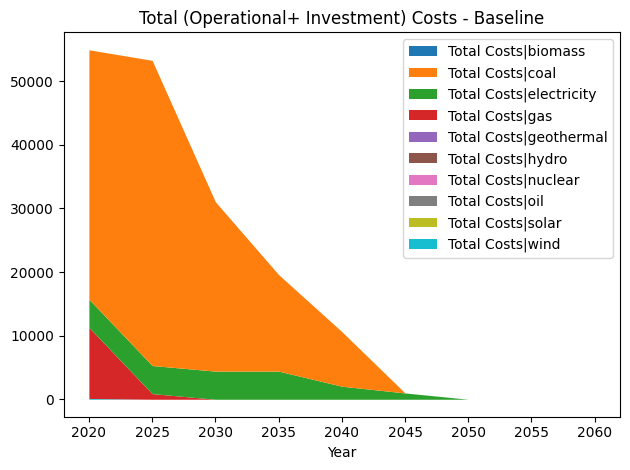

In [46]:
data = df_cost.filter(scenario = 'baseline', variable=
    ["Total Costs|coal","Total Costs|biomass",
    "Total Costs|electricity",
    "Total Costs|oil",
    "Total Costs|gas",
    "Total Costs|geothermal",
    "Total Costs|solar",
    "Total Costs|wind",
    "Total Costs|hydro",
    "Total Costs|nuclear"],
              year = plotyrs, region = 'Alberta')

data.plot.stack(title = 'Total (Operational+ Investment) Costs - Baseline')
plt.legend(loc=1)
plt.tight_layout()
plt.show()


Now making another scenario cloned from baseline to add other policies. 

Policy No. 1
Baseline - NDC 
Implement Canada's commitments 


In [ ]:
msgbas = msg.clone(modelName, 'Emissons bounds','Introducing Canadas goals',
                     keep_solution=False)

In [ ]:
msgbas.check_out()

In [ ]:
msg.par('emiss')

In [ ]:

def expand_grid(dictionary):
    return pd.DataFrame([row for row in product(*dictionary.values())], 
                       columns=dictionary.keys())


In [ ]:
  
    
year_df = [2020, 2025, 2030, 2035, 2040 ,2045 ,2050 ,2055 ,2060 ]


dic = {
    'node': [nodeName],
    'type_emission':[str('TCE')],
    'type_tec':[str('all')],
    'type_year': [2020, 2025, 2030, 2035, 2040 ,2045 ,2050 ,2055 ,2060 ],
    'value':     [629, 572, 526, 450 , 375, 320, 255, 200, 150],
    'unit':[str('-')]}

df = expand_grid(dic)
df = df.iloc[0:9]
df['type_year'] = year_df



In [ ]:
# msgbas.remove_solution()

In [ ]:
msgbas.check_out()

In [ ]:
#msgSDG.add_par('bound_emission',df)
msgbas.add_par('bound_emission', df)
msgbas.commit('emissions bounded ')

In [ ]:
msgbas.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

In [ ]:
from message_ix.reporting import Reporter
from update_units import unit_correction
import numpy as np
unit_correct = False  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

if unit_correct:
    msg = msg.clone(keep_solution=False)
    unit_correction(mp, msg)
    caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)
    # Solving the model
    msg.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

#%% Generating reporter
rep = Reporter.from_scenario(msgbas)
report = rep.get('message:default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()

    # Plotted years
years = msgbas.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
c = report_df.select_dtypes(include=[np.number]) * 8.76
report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = out_flows.append(in_flows)

In [ ]:
report_df.to_csv('MESSAGE_CANADA_baselinendc.csv')

In [ ]:
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('emis', 'Emissions', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)

In [ ]:
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
pdf = pyam_df.copy()

In [ ]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

In [ ]:
pdf.filter(variable = 'Primary Energy|oil').timeseries()

In [ ]:
pdf.filter( variable=["Primary Energy|renewable|solar",
                                            #"Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs).stack_plot(total=True,
                                        title = 'Primary Energy by fuel - Baseline Scenario')

In [ ]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

In [ ]:
df_emis.timeseries()

In [ ]:
df_emis.filter( variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement",
    "Emissions|CO2|oil trade",
    "Emissions|CO2|gas trade"],
              year = plotyrs,region = 'Canada').stack_plot(total=True,
                                         title = 'CO2 Emissions - Baseline Scenario')

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('MESSAGE_CANADA_baselinendc.csv')

In [ ]:
df['Model'].replace('CD_Links_SSP2_R14', 'MESSAGEix-Canada', inplace=True)

In [ ]:
df.head()

In [ ]:
df.to_csv('MESSAGE_CANADA_v1.csv')

In [ ]:
import pandas as pd

In [ ]:
iso = 'CAN'

In [ ]:
# SSP GDP data
ssp_gdp_df = pd.read_excel( str('OECD_SSP_GDP_PPP.xlsx'),
        'OECD_SSP_GDP_PPP',
        header = 0)
ssp_gdp_df = ssp_gdp_df.loc[ (  ssp_gdp_df.Region == iso ) ].reset_index(drop=True)

# SSP population data

ssp_pop_df = pd.read_excel(str('OECD_SSP_POP.xlsx'),
        'OECD_SSP_POP',
        header = 0)
ssp_pop_df = ssp_pop_df.loc[ (  ssp_pop_df.Region == iso  ) ].reset_index(drop=True)

In [ ]:
ssp_pop_df['Scenario'] = ssp_pop_df['Scenario'].str.replace('_v9_130325', '')
ssp_gdp_df['Scenario'] = ssp_gdp_df['Scenario'].str.replace('_v9_130325', '')

In [ ]:
ssp_gdp_df

In [ ]:
import pyam
import matplotlib.pyplot as plt
import pyam

pop_df = pyam.IamDataFrame(ssp_pop_df)
gdp_df = pyam.IamDataFrame(ssp_gdp_df)

In [ ]:
pop_df.head()

In [ ]:
pop_df.plot(color='scenario', title='Population Projections of Canada across SSPs')

In [ ]:
gdp_df.plot(color='scenario', title='GDP Projections of Canada across SSPs')

In [ ]:
mp.add_unit('tCO2/kWa')
mp.add_unit('MtCO2')

In [ ]:
msgbas.set('type_emission')

In [ ]:

msgbas.add_par('bound_emission', ['Canada', 'TCE', 'all', 'cumulative'],
             value=700., unit='MtCO2')

In [ ]:
msgbas.commit('adding emissions bound')

In [ ]:
msgbas.solve()

In [ ]:
msgbas.scenario

In [ ]:
msgbas.par('bound_emission')

In [ ]:
msgCT = msgbas.clone(modelName, 'carbon_bound_by_year','introducing a carbon tax',
                             keep_solution=False)
msgCT.check_out()

In [ ]:
emissions = msgCT.var('EMISS')
emissions

In [ ]:

emission_prices_by_year = msg.var('PRICE_EMISSION')
emission_prices_by_year

In [ ]:

scen_tax = base.clone(model, 'carbon_tax','introducing a carbon tax',
                      keep_solution=False)
scen_tax.check_out()

In [ ]:
years

In [ ]:

base_tax_emission = {
    'node': 'Canada',
    'type_year': years,
    'type_tec': 'all',
    'unit': 'USD/tCO2',
    'type_emission': 'GHG',
    'value': emission_prices.set_index('year').lvl
}

In [ ]:


# in case you need to add the new unit to the platform
mp.add_unit('USD/tCO2')

tax_emission = make_df(base_tax_emission)
scen_tax.add_par('tax_emission', tax_emission)
scen_tax.par('tax_emission')

In [ ]:

scen_tax.commit(comment='setting taxes on emissions')

In [ ]:
scen_tax.var('EMISS', {'node': 'Westeros'})